# Emmanuel's Face Detection and Recognition Notebook

**Purpose:** I detect one clear face, align it, create an SFace embedding, enrol consenting people, use separate validation images to choose the match threshold, then evaluate an untouched test set.

**Why a notebook:** I can run one small Python step at a time and inspect the face image and matching result. The dashboard still imports the reusable Python module; this notebook teaches and evaluates that same pipeline.

**Important:** SFace is already pretrained. My enrollment images build an identity gallery; they do not train SFace. Similarity is not the probability that two images show the same person. YuNet + SFace do not detect printed-photo or screen attacks.


**Colab GPU note:** Select **Runtime → Change runtime type → T4 GPU** (or the available GPU) before running. MiniFASNet uses CUDA only when ONNX Runtime reports a CUDA provider. YuNet, SFace, and MediaPipe FaceMesh still run on CPU in this notebook. The saved timing below is the local CPU baseline; rerun the video section on Colab to compare.

## 1. Install or confirm the Python packages

I use OpenCV's face detector and face recognizer APIs plus NumPy. I install `opencv-contrib-python-headless` because it includes the YuNet and SFace APIs without requiring a desktop window. In Colab, run this cell once if those imports are missing.


In [1]:
# If OpenCV or NumPy is missing in this notebook runtime, uncomment and run:
# %pip install "opencv-contrib-python-headless>=4.10,<5" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "remotezip>=0.12,<1"

from pathlib import Path
from hashlib import sha256
from urllib.request import urlopen
import os
import importlib.util
import subprocess
import sys
import time
import zipfile

# I check whether this Colab runtime has an NVIDIA GPU.
gpu_runtime_available = False
try:
    import torch
    gpu_runtime_available = torch.cuda.is_available()
except ImportError:
    pass

from importlib.metadata import PackageNotFoundError, version

def installed_package_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return None

if importlib.util.find_spec("mediapipe") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mediapipe==0.10.21"])

cpu_onnx_version = installed_package_version("onnxruntime")
gpu_onnx_version = installed_package_version("onnxruntime-gpu")
if gpu_runtime_available and gpu_onnx_version is None:
    # ONNX Runtime documents CUDA 12.x support for its 1.20.x GPU package.
    if cpu_onnx_version is not None:
        subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "onnxruntime"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "onnxruntime-gpu==1.26.0"])
elif not gpu_runtime_available and cpu_onnx_version is None and gpu_onnx_version is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "onnxruntime"])

print("NVIDIA GPU available:", gpu_runtime_available)

import cv2
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


OpenCV: 4.11.0
NumPy: 1.26.4


## 2. Get the verified face models

I use YuNet to find facial landmarks and SFace to create 128-number embeddings. The notebook checks SHA-256 so an incomplete or unexpected model file is not used. I do not use FaceNet here: it is part of our literature review, while these OpenCV Zoo models are the pipeline available in this project.


In [2]:
FACE_MODELS = {
    "face_detection_yunet_2023mar.onnx": {
        "url": "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
        "sha256": "8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4",
    },
    "minifasnet_v2.onnx": {
        "url": "https://github.com/yakhyo/face-anti-spoofing/releases/download/weights/MiniFASNetV2.onnx",
        "sha256": "b32929adc2d9c34b9486f8c4c7bc97c1b69bc0ea9befefc380e4faae4e463907",
    },
    "face_recognition_sface_2021dec.onnx": {
        "url": "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx",
        "sha256": "0ba9fbfa01b5270c96627c4ef784da859931e02f04419c829e83484087c34e79",
    },
}

# In this project notebook, the models folder is one level above this notebook.
# In Colab, it is normally beside the notebook, so I accept either location.
MODEL_NAMES = tuple(FACE_MODELS)
MODEL_DIR = Path("models")
for candidate_dir in (Path("models"), Path("../models")):
    if all((candidate_dir / name).is_file() for name in MODEL_NAMES):
        MODEL_DIR = candidate_dir
        break
MODEL_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    digest = sha256()
    with Path(path).open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def get_verified_model(filename, details):
    path = MODEL_DIR / filename
    if not path.exists():
        print("Downloading", filename)
        with urlopen(details["url"], timeout=120) as response:
            path.write_bytes(response.read())
    actual = file_sha256(path)
    if actual != details["sha256"]:
        raise ValueError(f"Checksum did not match for {filename}. Do not use this file.")
    print("Verified:", filename)
    return path

yunet_path = get_verified_model("face_detection_yunet_2023mar.onnx", FACE_MODELS["face_detection_yunet_2023mar.onnx"])
sface_path = get_verified_model("face_recognition_sface_2021dec.onnx", FACE_MODELS["face_recognition_sface_2021dec.onnx"])
pad_model_path = get_verified_model("minifasnet_v2.onnx", FACE_MODELS["minifasnet_v2.onnx"])


Verified: face_detection_yunet_2023mar.onnx


Verified: face_recognition_sface_2021dec.onnx
Verified: minifasnet_v2.onnx


## 3. Create the detector and recognizer once

I load each model once and reuse it. This avoids paying the model-loading cost for every image and helps keep processing quicker.


In [3]:
DETECTION_THRESHOLD = 0.70  # YuNet face-detection score, not identity similarity.
MAX_IMAGE_SIDE = 640           # Keep image detail while bounding inference cost.

face_detector = cv2.FaceDetectorYN.create(
    str(yunet_path), "", (320, 320),
    score_threshold=DETECTION_THRESHOLD,
    nms_threshold=0.30,
)
face_recognizer = cv2.FaceRecognizerSF.create(str(sface_path), "")
print("YuNet and SFace are ready.")


YuNet and SFace are ready.


## 4. Detect, align, and represent one face

I require exactly one detectable face in each image. This prevents me from silently enrolling or matching the wrong person in a group photo. I align facial landmarks to standardize the crop before SFace compares it. I use shadow enhancement only for YuNet detection; SFace receives the original image so enrollment and testing use the same appearance pipeline. If the camera captured no facial detail, software enhancement cannot recreate it.


## 5. Check for photo and screen presentation attacks

I use MiniFASNet V2 as a **passive presentation-attack check**. It estimates whether a face crop looks like a live camera face or a spoof such as a print or screen. It does not identify the person, and its score is not a probability that the person is live. I keep the threshold provisional until I validate it with separate camera captures from my own setup.

I use the official ONNX export and verify its checksum before loading it. The model expects an expanded face crop at 80 × 80 pixels. My crop and tensor layout follow the ONNX inference reference. The model was not trained or evaluated on my camera, so I must test real, printed, and screen-replay samples captured with the same camera and distance.

Reference: [MiniFASNet ONNX inference and model](https://github.com/yakhyo/face-anti-spoofing), [Apache-2.0 license](https://github.com/yakhyo/face-anti-spoofing/blob/main/LICENSE).


In [4]:
import onnxruntime as ort

PAD_REAL_THRESHOLD = 0.50  # Provisional; choose this with my separate PAD validation captures.
PAD_CROP_SCALE = 2.7       # MiniFASNet V2 reference crop scale.
pad_providers_available = ort.get_available_providers()
pad_providers = (
    ["CUDAExecutionProvider", "CPUExecutionProvider"]
    if "CUDAExecutionProvider" in pad_providers_available
    else ["CPUExecutionProvider"]
)
try:
    pad_session = ort.InferenceSession(
        str(MODEL_DIR / "minifasnet_v2.onnx"),
        providers=pad_providers,
    )
except Exception as error:
    print("I could not start the GPU provider; I will use CPU for MiniFASNet:", error)
    pad_session = ort.InferenceSession(
        str(MODEL_DIR / "minifasnet_v2.onnx"),
        providers=["CPUExecutionProvider"],
    )
print("MiniFASNet providers:", pad_session.get_providers())
pad_input = pad_session.get_inputs()[0]
pad_output = pad_session.get_outputs()[0]
pad_input_name = pad_input.name
pad_output_name = pad_output.name
pad_height, pad_width = int(pad_input.shape[2]), int(pad_input.shape[3])

def make_pad_crop(image_bgr, face_row):
    """Make the enlarged 80-by-80 BGR crop expected by MiniFASNet V2."""
    image_height, image_width = image_bgr.shape[:2]
    x, y, box_width, box_height = [float(value) for value in face_row[:4]]
    if box_width <= 0 or box_height <= 0:
        raise ValueError("I need a positive face box for the anti-spoof check.")

    scale = min(
        (image_height - 1) / box_height,
        (image_width - 1) / box_width,
        PAD_CROP_SCALE,
    )
    center_x = x + box_width / 2
    center_y = y + box_height / 2
    crop_width = box_width * scale
    crop_height = box_height * scale
    x1 = max(0, int(center_x - crop_width / 2))
    y1 = max(0, int(center_y - crop_height / 2))
    x2 = min(image_width, int(center_x + crop_width / 2))
    y2 = min(image_height, int(center_y + crop_height / 2))
    crop = image_bgr[y1:y2, x1:x2]
    if crop.size == 0:
        raise ValueError("I could not crop this face for the anti-spoof check.")
    return cv2.resize(crop, (pad_width, pad_height), interpolation=cv2.INTER_LINEAR)

def check_presentation_attack(image_bgr, face_row):
    """Return MiniFASNet real and spoof scores for one face."""
    crop = make_pad_crop(image_bgr, face_row)
    # The reference ONNX implementation uses the OpenCV BGR crop, CHW layout, and raw 0–255 values.
    tensor = np.transpose(crop.astype(np.float32), (2, 0, 1))[None, ...]
    logits = pad_session.run([pad_output_name], {pad_input_name: tensor})[0]
    logits = np.asarray(logits, dtype=np.float32).reshape(1, -1)
    logits -= np.max(logits, axis=1, keepdims=True)
    probabilities = np.exp(logits)
    probabilities /= np.sum(probabilities, axis=1, keepdims=True)
    # In the reference implementation, class index 1 is real; every other class is spoof.
    real_score = float(probabilities[0, 1])
    spoof_score = float(1.0 - real_score)
    label = "REAL_CANDIDATE" if real_score >= PAD_REAL_THRESHOLD else "SPOOF_SUSPECTED"
    return {"label": label, "real_score": real_score, "spoof_score": spoof_score}

print("MiniFASNet V2 is ready. The 0.50 decision threshold is provisional.")

MiniFASNet V2 is ready. The 0.50 decision threshold is provisional.


## 6. Measure an eye-blink cue with MediaPipe FaceMesh

I use MediaPipe FaceMesh to find eye landmarks, then calculate the eye aspect ratio (EAR). A video may show a blink when EAR goes from open, to closed, and back to open. I treat a detected blink as **one liveness cue only**. It is not proof of liveness: a screen replay can show a recorded blink. I combine this cue with MiniFASNet, and I report uncertain cases instead of treating missing landmarks as a live face.

I run FaceMesh on a crop for each detected face. This keeps the face landmarks associated with the YuNet box. I process every video frame in the test so a short blink is less likely to be skipped; this can increase latency.

Reference: [Google MediaPipe Face Landmarker / Face Mesh landmarks](https://developers.google.com/edge/mediapipe/solutions/vision/face_landmarker?tab=Python).


In [5]:
import mediapipe as mp

if not hasattr(mp, "solutions"):
    raise RuntimeError(
        "I need MediaPipe FaceMesh. If this import is missing in Colab, restart the runtime "
        "after the package-install cell and run the notebook from the top."
    )

face_mesh = mp.solutions.face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5,
)

# MediaPipe FaceMesh points around the six landmarks on each eye.
LEFT_EYE_POINTS = (33, 160, 158, 133, 153, 144)
RIGHT_EYE_POINTS = (362, 385, 387, 263, 373, 380)
EAR_OPEN_THRESHOLD = 0.22
EAR_CLOSED_THRESHOLD = 0.17
MAX_BLINK_GAP_FRAMES = 20

def eye_aspect_ratio(eye_points):
    """Calculate the eye aspect ratio from six (x, y) points."""
    vertical_a = np.linalg.norm(eye_points[1] - eye_points[5])
    vertical_b = np.linalg.norm(eye_points[2] - eye_points[4])
    horizontal = np.linalg.norm(eye_points[0] - eye_points[3])
    if horizontal == 0:
        return None
    return float((vertical_a + vertical_b) / (2.0 * horizontal))

def find_face_ear(frame_bgr, face_row):
    """Return mean left/right EAR for one YuNet face, or None if unclear."""
    frame_height, frame_width = frame_bgr.shape[:2]
    x, y, width, height = [int(value) for value in face_row[:4]]
    pad_x, pad_y = int(width * 0.25), int(height * 0.25)
    x1, y1 = max(0, x - pad_x), max(0, y - pad_y)
    x2, y2 = min(frame_width, x + width + pad_x), min(frame_height, y + height + pad_y)
    face_crop = frame_bgr[y1:y2, x1:x2]
    if face_crop.size == 0:
        return None

    mesh_result = face_mesh.process(cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB))
    if not mesh_result.multi_face_landmarks:
        return None

    landmarks = mesh_result.multi_face_landmarks[0].landmark
    crop_height, crop_width = face_crop.shape[:2]
    points = np.array(
        [(point.x * crop_width, point.y * crop_height) for point in landmarks],
        dtype=np.float32,
    )
    left_ear = eye_aspect_ratio(points[list(LEFT_EYE_POINTS)])
    right_ear = eye_aspect_ratio(points[list(RIGHT_EYE_POINTS)])
    if left_ear is None or right_ear is None:
        return None
    return (left_ear + right_ear) / 2.0

def new_liveness_state():
    """Create blink state for one video track."""
    return {"saw_open_eye": False, "closed_start": None, "closed_samples": 0, "blink_count": 0}

def update_blink_state(state, ear, frame_number):
    """Count an open-close-open eye sequence; return the updated count."""
    if ear is None:
        return state["blink_count"]
    if ear >= EAR_OPEN_THRESHOLD:
        closed_start = state["closed_start"]
        if closed_start is not None:
            gap = frame_number - closed_start
            if state["closed_samples"] >= 1 and 1 <= gap <= MAX_BLINK_GAP_FRAMES:
                state["blink_count"] += 1
            state["closed_start"] = None
            state["closed_samples"] = 0
        state["saw_open_eye"] = True
    elif ear <= EAR_CLOSED_THRESHOLD and state["saw_open_eye"]:
        if state["closed_start"] is None:
            state["closed_start"] = frame_number
        state["closed_samples"] += 1
    return state["blink_count"]

print("MediaPipe FaceMesh and the blink-cue check are ready.")

MediaPipe FaceMesh and the blink-cue check are ready.


In [6]:
def improve_dark_detection(image_bgr):
    # Lift shadow detail for detection only; keep the original for SFace.
    ycrcb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YCrCb)
    luminance = ycrcb[:, :, 0]
    if float(np.mean(luminance)) < 100:
        ycrcb[:, :, 0] = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(luminance)
        return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)
    return image_bgr

def read_bgr(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"I could not read this image: {image_path}")
    return image

def make_embedding(image_bgr):
    # Return a unit-length SFace vector and the aligned face image.
    if image_bgr is None or image_bgr.size == 0 or image_bgr.ndim != 3:
        raise ValueError("I need a nonempty colour image.")
    if image_bgr.shape[2] != 3 or image_bgr.dtype != np.uint8:
        raise ValueError("I need a uint8 BGR colour image.")

    height, width = image_bgr.shape[:2]
    scale = min(1.0, MAX_IMAGE_SIDE / max(height, width))
    resized = cv2.resize(
        image_bgr,
        (max(1, round(width * scale)), max(1, round(height * scale))),
        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR,
    )

    detect_image = improve_dark_detection(resized)
    face_detector.setInputSize((resized.shape[1], resized.shape[0]))
    _, faces = face_detector.detect(detect_image)
    if faces is None or len(faces) != 1:
        found = 0 if faces is None else len(faces)
        raise ValueError(f"I expected exactly one clear face, but found {found}.")

    aligned = face_recognizer.alignCrop(resized, faces[0])
    vector = face_recognizer.feature(aligned).flatten().astype(np.float32)
    length = float(np.linalg.norm(vector))
    if vector.shape != (128,) or not np.isfinite(vector).all() or length == 0:
        raise ValueError("SFace returned an invalid embedding.")
    return vector / length, aligned, faces[0]

def show_face(image_bgr, title="Face image"):
    plt.figure(figsize=(5, 4))
    plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


## 7. Prepare separate enrollment, validation, and test images

I keep the three sets separate. Enrollment builds the gallery, validation chooses the threshold, and test is used once for final evaluation. Each file must be a distinct capture; do not split augmented copies of one photo. Known people need images in all three sets. People in `Unknown` must never be enrolled. Aim for at least 20 test captures. An exact 60/20/20 split needs 100 images to put 20 in test; 80 images gives 48/16/16.

For a repeatable practice run, I download a small subset from Microsoft's **DigiFace-1M**. It contains generated identities, not consenting volunteers, and is licensed for non-commercial research. This lets me practice the split and code without collecting real people's faces. It cannot establish real-camera performance, lighting robustness, or spoof resistance. For the project evaluation, I must still test consented camera/video captures.

```text
face_images/
  enroll/
    Ada Lovelace/   (at least 3 separate real captures)
      front.jpg
      slight_turn.jpg
  validation/
    Ada Lovelace/   (separate captures of an enrolled person)
      validation_1.jpg
    Unknown/        (people absent from the gallery)
      unknown_1.jpg
  test/
    Ada Lovelace/   (separate captures, not used for enrolment or validation)
      held_out_1.jpg
    Unknown/        (people absent from the gallery)
      held_out_unknown_1.jpg
```

Source: [Microsoft DigiFace-1M](https://github.com/microsoft/DigiFace1M). I read and accepted its non-commercial research terms. The notebook downloads only selected files into the ignored `private_data/` folder. I can set `USE_DIGIFACE_SAMPLE = False` and provide my own consented images instead. I keep images and embeddings off GitHub. I tune the threshold using validation only; I do not tune it after looking at test results.

Dataset paper: Bae et al., *DigiFace-1M: 1 Million Digital Face Images for Face Recognition*, WACV 2023.


In [7]:
USE_DIGIFACE_SAMPLE = True
DATA_DIR = Path("private_data/digiface1m_subset/face_images")

if USE_DIGIFACE_SAMPLE:
    # I fetch 140 selected PNGs by byte-range from the official 2.9 GB archive.
    # remotezip reads only the selected image files instead of downloading the full archive.
    from remotezip import RemoteZip

    DIGIFACE_URL = (
        "https://facesyntheticspubwedata.z6.web.core.windows.net/wacv-2023/"
        "subjects_0-1999_72_imgs.zip"
    )
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    if not any(DATA_DIR.rglob("*.png")):
        with RemoteZip(DIGIFACE_URL, support_suffix_range=False) as archive:
            # Known identities: 3 gallery images, 1 validation image, 1 test image each.
            for identity_id in range(20):
                person_name = f"Synthetic_{identity_id:04d}"
                split_paths = {
                    "enroll": range(0, 3),
                    "validation": range(3, 4),
                    "test": range(4, 5),
                }
                for split_name, image_numbers in split_paths.items():
                    person_folder = DATA_DIR / split_name / person_name
                    person_folder.mkdir(parents=True, exist_ok=True)
                    for image_number in image_numbers:
                        member = f"{identity_id}/{image_number}.png"
                        (person_folder / f"capture_{image_number}.png").write_bytes(
                            archive.read(member)
                        )

            # Unknown validation and test identities are disjoint from each other.
            for split_name, identity_range in (
                ("validation", range(20, 40)),
                ("test", range(40, 60)),
            ):
                unknown_folder = DATA_DIR / split_name / "Unknown"
                unknown_folder.mkdir(parents=True, exist_ok=True)
                for identity_id in identity_range:
                    member = f"{identity_id}/0.png"
                    (unknown_folder / f"synthetic_unknown_{identity_id:04d}.png").write_bytes(
                        archive.read(member)
                    )
    print("Small synthetic DigiFace-1M practice set is ready at:", DATA_DIR)
else:
    # In Colab, upload a ZIP containing face_images/enroll, validation, and test.
    try:
        from google.colab import files
        IN_COLAB = True
    except ImportError:
        IN_COLAB = False

    DATA_DIR = Path("face_images")
    if IN_COLAB:
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(zip_names) != 1:
            raise ValueError("Upload exactly one ZIP containing the face_images folders.")
        DATA_DIR.mkdir(exist_ok=True)
        with zipfile.ZipFile(zip_names[0]) as archive:
            for item in archive.infolist():
                destination = (DATA_DIR / item.filename).resolve()
                if not destination.is_relative_to(DATA_DIR.resolve()):
                    raise ValueError("The ZIP contains a path outside the data folder.")
            archive.extractall(DATA_DIR)
        if (DATA_DIR / "face_images").is_dir():
            DATA_DIR = DATA_DIR / "face_images"

enroll_dir = DATA_DIR / "enroll"
validation_dir = DATA_DIR / "validation"
test_dir = DATA_DIR / "test"
missing_folders = [
    name for name, folder in (
        ("enroll", enroll_dir),
        ("validation", validation_dir),
        ("test", test_dir),
    )
    if not folder.is_dir()
]
if missing_folders:
    raise FileNotFoundError(
        "I need separate enroll, validation, and test folders. Missing: "
        + ", ".join(missing_folders)
    )
print("Enrollment people:", [p.name for p in enroll_dir.iterdir() if p.is_dir()])
print("Validation labels:", [p.name for p in validation_dir.iterdir() if p.is_dir()])
print("Test labels:", [p.name for p in test_dir.iterdir() if p.is_dir()])


Small synthetic DigiFace-1M practice set is ready at: private_data\digiface1m_subset\face_images
Enrollment people: ['Synthetic_0000', 'Synthetic_0001', 'Synthetic_0002', 'Synthetic_0003', 'Synthetic_0004', 'Synthetic_0005', 'Synthetic_0006', 'Synthetic_0007', 'Synthetic_0008', 'Synthetic_0009', 'Synthetic_0010', 'Synthetic_0011', 'Synthetic_0012', 'Synthetic_0013', 'Synthetic_0014', 'Synthetic_0015', 'Synthetic_0016', 'Synthetic_0017', 'Synthetic_0018', 'Synthetic_0019']
Validation labels: ['Synthetic_0000', 'Synthetic_0001', 'Synthetic_0002', 'Synthetic_0003', 'Synthetic_0004', 'Synthetic_0005', 'Synthetic_0006', 'Synthetic_0007', 'Synthetic_0008', 'Synthetic_0009', 'Synthetic_0010', 'Synthetic_0011', 'Synthetic_0012', 'Synthetic_0013', 'Synthetic_0014', 'Synthetic_0015', 'Synthetic_0016', 'Synthetic_0017', 'Synthetic_0018', 'Synthetic_0019', 'Unknown']
Test labels: ['Synthetic_0000', 'Synthetic_0001', 'Synthetic_0002', 'Synthetic_0003', 'Synthetic_0004', 'Synthetic_0005', 'Synthetic

## 8. Enrol people from separate real captures

I make one normalized template per person by averaging that person's normalized capture embeddings and normalizing the average again. This uses several real views without pretending that synthetic copies add new evidence.


In [8]:
def image_files(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    return sorted(path for path in folder.rglob("*") if path.suffix.lower() in extensions)

def normalized_average(vectors):
    average = np.mean(np.stack(vectors), axis=0)
    length = float(np.linalg.norm(average))
    if not np.isfinite(average).all() or length == 0:
        raise ValueError("I could not make a valid average template.")
    return (average / length).astype(np.float32)

gallery = {}
enrollment_counts = {}

for person_folder in sorted(enroll_dir.iterdir()):
    if not person_folder.is_dir():
        continue
    captures = image_files(person_folder)
    if not captures:
        print("Skipping empty folder:", person_folder.name)
        continue
    vectors = []
    for path in captures:
        try:
            vector, aligned_face, _ = make_embedding(read_bgr(path))
            vectors.append(vector)
        except ValueError as error:
            print("Skipping unclear enrollment image:", path.name, "—", error)
    if len(vectors) < 2:
        print("Skipping identity with fewer than 2 clear enrollment images:", person_folder.name)
        continue
    gallery[person_folder.name] = normalized_average(vectors)
    enrollment_counts[person_folder.name] = f"{len(vectors)}/{len(captures)} clear captures"

if not gallery:
    raise ValueError("I need at least one enrolled person with a clear face image.")
print("Enrolled capture counts:", enrollment_counts)
print("Profiles are held in this notebook memory; I have not saved the face images.")


Skipping unclear enrollment image: capture_1.png — I expected exactly one clear face, but found 0.


Enrolled capture counts: {'Synthetic_0000': '3/3 clear captures', 'Synthetic_0001': '3/3 clear captures', 'Synthetic_0002': '3/3 clear captures', 'Synthetic_0003': '3/3 clear captures', 'Synthetic_0004': '3/3 clear captures', 'Synthetic_0005': '3/3 clear captures', 'Synthetic_0006': '3/3 clear captures', 'Synthetic_0007': '3/3 clear captures', 'Synthetic_0008': '3/3 clear captures', 'Synthetic_0009': '3/3 clear captures', 'Synthetic_0010': '3/3 clear captures', 'Synthetic_0011': '2/3 clear captures', 'Synthetic_0012': '3/3 clear captures', 'Synthetic_0013': '3/3 clear captures', 'Synthetic_0014': '3/3 clear captures', 'Synthetic_0015': '3/3 clear captures', 'Synthetic_0016': '3/3 clear captures', 'Synthetic_0017': '3/3 clear captures', 'Synthetic_0018': '3/3 clear captures', 'Synthetic_0019': '3/3 clear captures'}
Profiles are held in this notebook memory; I have not saved the face images.


## 9. Choose the threshold using validation images only

I normalize the embedding because SFace compares vector direction; after normalization, a dot product gives cosine similarity quickly. I keep the ambiguity margin provisional and use only validation images to choose the similarity threshold. Test images are not used to tune settings. I never describe similarity as a probability.


In [9]:
SIMILARITY_THRESHOLD = 0.40  # Replaced below using validation images only.
AMBIGUITY_MARGIN = 0.05       # Provisional gap required over the second-best identity.

def compare_embedding(query, references):
    scores = {
        name: float(np.clip(np.dot(query, reference), -1.0, 1.0))
        for name, reference in references.items()
    }
    ranked = sorted(scores.items(), key=lambda pair: (-pair[1], pair[0]))
    candidate, best_score = ranked[0]
    second_score = ranked[1][1] if len(ranked) > 1 else None
    score_gap = None if second_score is None else best_score - second_score

    if best_score < SIMILARITY_THRESHOLD:
        status, accepted_name = "UNKNOWN", None
        reason = "No enrolled reference passed the similarity threshold."
    elif score_gap is not None and score_gap < AMBIGUITY_MARGIN:
        status, accepted_name = "UNCERTAIN", None
        reason = "The best two enrolled references are too close."
    else:
        status, accepted_name = "KNOWN", candidate
        reason = "The score passed the provisional decision rules."

    return {
        "status": status,
        "accepted_name": accepted_name,
        "closest_candidate": candidate,
        "cosine_similarity": best_score,
        "second_best_gap": score_gap,
        "reason": reason,
        "all_scores": scores,
    }

def recognize_image(image_path):
    vector, aligned_face, _ = make_embedding(read_bgr(image_path))
    return compare_embedding(vector, gallery), aligned_face

def tune_threshold(validation_folder):
    validation_rows = []
    for label_folder in sorted(validation_folder.iterdir()):
        if not label_folder.is_dir():
            continue
        expected = label_folder.name
        is_unknown = expected.casefold() == "unknown"
        for path in image_files(label_folder):
            try:
                vector, _, _ = make_embedding(read_bgr(path))
                scores = {
                    name: float(np.clip(np.dot(vector, template), -1.0, 1.0))
                    for name, template in gallery.items()
                }
                ranked_scores = sorted(scores.items(), key=lambda pair: (-pair[1], pair[0]))
                best_name, best_score = ranked_scores[0]
                second_score = ranked_scores[1][1] if len(ranked_scores) > 1 else None
                gap = None if second_score is None else best_score - second_score
                validation_rows.append((expected, is_unknown, best_name, best_score, gap))
            except ValueError as error:
                print("Skipping unclear validation image:", path.name, "—", error)

    if not validation_rows:
        raise ValueError("I need clear validation images before tuning the threshold.")
    if not any(row[1] for row in validation_rows) or not any(not row[1] for row in validation_rows):
        raise ValueError("Validation needs both known identities and an Unknown folder.")

    candidates = sorted({0.0, 1.0, *(row[3] for row in validation_rows)})
    known_rows = [row for row in validation_rows if not row[1]]
    unknown_rows = [row for row in validation_rows if row[1]]
    best_threshold = None
    best_accuracy = -1.0
    for threshold in candidates:
        known_correct = sum(
            best_score >= threshold
            and (gap is None or gap >= AMBIGUITY_MARGIN)
            and best_name == expected
            for expected, _, best_name, best_score, gap in known_rows
        )
        unknown_correct = sum(
            best_score < threshold
            for _, _, _, best_score, _ in unknown_rows
        )
        # Give known and unknown examples equal weight even if folder counts differ.
        accuracy = 0.5 * (
            known_correct / len(known_rows)
            + unknown_correct / len(unknown_rows)
        )
        if accuracy >= best_accuracy:
            best_accuracy = accuracy
            best_threshold = threshold
    return best_threshold, best_accuracy, len(validation_rows)

SIMILARITY_THRESHOLD, validation_accuracy, validation_count = tune_threshold(validation_dir)
print("Validation images used:", validation_count)
print("Chosen cosine-similarity threshold:", round(SIMILARITY_THRESHOLD, 3))
print("Validation accuracy at chosen threshold:", round(validation_accuracy, 3))
print("This is threshold tuning, not the final test result.")


Validation images used: 40
Chosen cosine-similarity threshold: 0.586
Validation accuracy at chosen threshold: 0.975
This is threshold tuning, not the final test result.


## 10. Evaluate the untouched test images and inspect results

I run each test image once after freezing the validation threshold. I put people missing from the gallery in `test/Unknown`. I report the number of test images, correct decisions, unknown false accepts, and known false rejects. Fewer than 20 images triggers a reminder to collect more; this is not a claim of general accuracy.


{'image': 'capture_4.png', 'expected_folder': 'Synthetic_0000', 'decision': 'UNKNOWN', 'accepted_name': None, 'closest_candidate': 'Synthetic_0000', 'cosine_similarity': 0.512, 'correct_for_this_label': False, 'reason': 'No enrolled reference passed the similarity threshold.'}
{'image': 'capture_4.png', 'expected_folder': 'Synthetic_0001', 'decision': 'KNOWN', 'accepted_name': 'Synthetic_0001', 'closest_candidate': 'Synthetic_0001', 'cosine_similarity': 0.813, 'correct_for_this_label': True, 'reason': 'The score passed the provisional decision rules.'}
{'image': 'capture_4.png', 'expected_folder': 'Synthetic_0002', 'decision': 'KNOWN', 'accepted_name': 'Synthetic_0002', 'closest_candidate': 'Synthetic_0002', 'cosine_similarity': 0.716, 'correct_for_this_label': True, 'reason': 'The score passed the provisional decision rules.'}
{'image': 'capture_4.png', 'expected_folder': 'Synthetic_0003', 'decision': 'KNOWN', 'accepted_name': 'Synthetic_0003', 'closest_candidate': 'Synthetic_0003', '

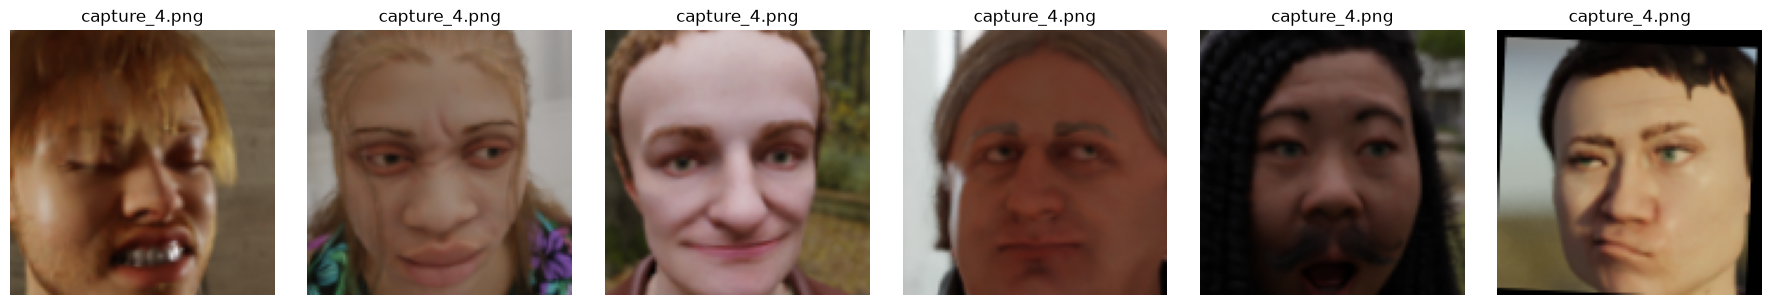

In [10]:
results = []
aligned_examples = []

for label_folder in sorted(test_dir.iterdir()):
    if not label_folder.is_dir():
        continue
    expected = label_folder.name
    is_unknown = expected.casefold() == "unknown"
    for path in image_files(label_folder):
        try:
            decision, aligned = recognize_image(path)
            if is_unknown:
                correct = decision["status"] == "UNKNOWN"
            else:
                correct = decision["accepted_name"] == expected
            results.append({
                "image": path.name,
                "expected_folder": expected,
                "decision": decision["status"],
                "accepted_name": decision["accepted_name"],
                "closest_candidate": decision["closest_candidate"],
                "cosine_similarity": round(decision["cosine_similarity"], 3),
                "correct_for_this_label": correct,
                "reason": decision["reason"],
            })
            if len(aligned_examples) < 6:
                aligned_examples.append((path.name, aligned))
        except ValueError as error:
            results.append({
                "image": path.name,
                "expected_folder": expected,
                "decision": "FACE_UNCLEAR",
                "accepted_name": None,
                "closest_candidate": None,
                "cosine_similarity": None,
                "correct_for_this_label": False,
                "reason": str(error),
            })

if not results:
    print("No test images found. Add separate images under face_images/test/ and rerun this cell.")
else:
    for row in results:
        print(row)
    print("\nImages evaluated:", len(results))
    print("Correct for these supplied labels:", sum(r["correct_for_this_label"] for r in results), "/", len(results))
    unknown_rows = [row for row in results if row["expected_folder"].casefold() == "unknown"]
    known_rows = [row for row in results if row["expected_folder"].casefold() != "unknown"]
    false_accepts = sum(row["decision"] == "KNOWN" for row in unknown_rows)
    false_rejects = sum(row["accepted_name"] != row["expected_folder"] for row in known_rows)
    print("Unknown false accepts:", false_accepts, "/", len(unknown_rows))
    print("Known false rejects or wrong identities:", false_rejects, "/", len(known_rows))
    if len(results) < 20:
        print("Reminder: collect at least 20 distinct test images for the planned evaluation.")
    print("This result describes only these supplied images and scenarios.")
    if aligned_examples:
        figure, axes = plt.subplots(1, len(aligned_examples), figsize=(3 * len(aligned_examples), 3))
        if len(aligned_examples) == 1:
            axes = [axes]
        for axis, (name, face) in zip(axes, aligned_examples):
            axis.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
            axis.set_title(name)
            axis.axis("off")
        plt.tight_layout()
        plt.show()


## 11. Test whether the recognizer confuses a pair of twins

There is no generic image set in this notebook that can answer the twins question. I need images of two consenting twins, captured separately with the same camera. I enroll each twin using one set of photos and test on different photos. This measures whether **this SFace setup** mixes up that pair; it does not make the model twin-proof.

```text
private_data/twin_test/enroll/Twin_A/   (at least 3 separate images)
private_data/twin_test/enroll/Twin_B/   (at least 3 separate images)
private_data/twin_test/test/Twin_A/     (different held-out images)
private_data/twin_test/test/Twin_B/     (different held-out images)
```

The report includes each twin's correct matches and cross-twin errors. With no consented twin images, the code explains the folder setup and does not invent a result.


In [11]:
TWIN_DIR = Path("private_data/twin_test")
TWIN_ENROLL_DIR = TWIN_DIR / "enroll"
TWIN_TEST_DIR = TWIN_DIR / "test"

def build_twin_gallery(enroll_folder):
    templates = {}
    for person_folder in sorted(enroll_folder.iterdir()):
        if not person_folder.is_dir():
            continue
        vectors = []
        for path in image_files(person_folder):
            try:
                vector, _, _ = make_embedding(read_bgr(path))
                vectors.append(vector)
            except ValueError as error:
                print("Skipping unclear twin enrollment image:", path.name, "—", error)
        if len(vectors) >= 2:
            templates[person_folder.name] = normalized_average(vectors)
        else:
            print("I need at least two clear enrollment captures for:", person_folder.name)
    return templates

if not TWIN_ENROLL_DIR.is_dir() or not TWIN_TEST_DIR.is_dir():
    print("Twin test not run yet. Add the four folders shown above using consented twin captures.")
else:
    twin_gallery = build_twin_gallery(TWIN_ENROLL_DIR)
    twin_names = sorted(twin_gallery)
    if len(twin_names) != 2:
        print("I need exactly two twin identity folders with at least two clear enrollment images each.")
    else:
        twin_results = []
        for actual_name in twin_names:
            person_test_folder = TWIN_TEST_DIR / actual_name
            for path in image_files(person_test_folder):
                try:
                    vector, _, _ = make_embedding(read_bgr(path))
                    scores = {name: float(np.dot(vector, template)) for name, template in twin_gallery.items()}
                    predicted_name = max(scores, key=scores.get)
                    twin_results.append({
                        "actual": actual_name,
                        "predicted": predicted_name,
                        "correct": predicted_name == actual_name,
                        "other_twin_score": scores[next(name for name in twin_names if name != actual_name)],
                        "top_score": scores[predicted_name],
                    })
                except ValueError as error:
                    print("Skipping unclear twin test image:", path.name, "—", error)

        if not twin_results:
            print("No usable held-out twin test images were found.")
        else:
            print("Twin test images:", len(twin_results))
            print("Correct pair-specific matches:", sum(row["correct"] for row in twin_results), "/", len(twin_results))
            print("Cross-twin identity errors:", sum(not row["correct"] for row in twin_results), "/", len(twin_results))
            for row in twin_results:
                print(row)
            print("This result applies only to this pair and these capture conditions.")

Twin test not run yet. Add the four folders shown above using consented twin captures.


## 12. Test a recorded video or a local camera

This cell reads a recorded clip, or a camera attached to the computer running Jupyter, and checks faces every second frame. I save an annotated MP4 plus average, median, and 95th-percentile face-processing time. On Colab I upload a video file; a Colab runtime cannot directly open the camera attached to my laptop. To try DroidCam locally, I set `VIDEO_SOURCE` to its camera index (often not `0`). This tests face recognition on frames; person tracking, restricted-zone crossings, and alert latency still need the full application test.


In [ ]:
# In Colab I download the Drive video directly into the temporary runtime.
from pathlib import Path
import importlib.util
import subprocess
import sys

VIDEO_SOURCE = Path("private_data/people_walking_test.mp4")
VIDEO_SOURCE.parent.mkdir(parents=True, exist_ok=True)

if not VIDEO_SOURCE.is_file():
    if importlib.util.find_spec("gdown") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown
    downloaded_path = gdown.download(
        id="1gwlxtnzoUwYbvfhgOqyCAP0Yr9N3pFiY",
        output=str(VIDEO_SOURCE),
        quiet=False,
    )
    if downloaded_path is None or not VIDEO_SOURCE.is_file() or VIDEO_SOURCE.stat().st_size == 0:
        raise RuntimeError("I could not download the shared video. Check its Drive sharing access.")

print("Video ready:", VIDEO_SOURCE)
print("File size (MB):", round(VIDEO_SOURCE.stat().st_size / (1024 * 1024), 2))


In [12]:
VIDEO_SOURCE = Path("private_data/people_walking_test.mp4")  # Or use 0 / the DroidCam index in local Jupyter.
VIDEO_OUTPUT = Path("private_data/video_results/people_walking_security_review.mp4")
FRAME_STEP = 1       # I inspect each frame so I have a better chance of observing short blinks.
MAX_VIDEO_FRAMES = 150
MAX_IMAGE_SIDE = 640
FACE_TRACK_DISTANCE = 0.8
TRACK_MIN_EMBEDDING_SIMILARITY = 0.60
video_tracks = {}
next_video_track_id = 1
used_video_track_ids = set()

def box_center_and_size(face_row):
    x, y, width, height = [float(value) for value in face_row[:4]]
    return np.array([x + width / 2, y + height / 2]), max(width, height, 1.0)

def get_video_track(face_row, frame_number, embedding):
    """Match recent position and SFace embedding so blinks do not pass between people."""
    global next_video_track_id
    center, face_size = box_center_and_size(face_row)
    choices = []
    for track_id, state in video_tracks.items():
        if track_id in used_video_track_ids or frame_number - state["last_seen"] > 3:
            continue
        if embedding is None or state["embedding"] is None:
            continue
        embedding_similarity = float(np.dot(embedding, state["embedding"]))
        if embedding_similarity < TRACK_MIN_EMBEDDING_SIMILARITY:
            continue
        distance = float(np.linalg.norm(center - state["center"]))
        allowed_distance = FACE_TRACK_DISTANCE * max(face_size, state["face_size"])
        if distance <= allowed_distance:
            choices.append((distance / allowed_distance + (1.0 - embedding_similarity), track_id))
    if choices:
        track_id = min(choices)[1]
        video_tracks[track_id]["center"] = center
        video_tracks[track_id]["face_size"] = face_size
        video_tracks[track_id]["last_seen"] = frame_number
        video_tracks[track_id]["embedding"] = embedding.copy()
    else:
        track_id = next_video_track_id
        next_video_track_id += 1
        video_tracks[track_id] = {
            "center": center,
            "face_size": face_size,
            "last_seen": frame_number,
            "embedding": None if embedding is None else embedding.copy(),
            "liveness": new_liveness_state(),
            "pad_real_scores": [],
        }
    used_video_track_ids.add(track_id)
    return track_id

def identify_faces_in_frame(frame_bgr, frame_number):
    height, width = frame_bgr.shape[:2]
    scale = min(1.0, MAX_IMAGE_SIDE / max(height, width))
    frame = cv2.resize(
        frame_bgr,
        (max(1, round(width * scale)), max(1, round(height * scale))),
        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR,
    )
    face_detector.setInputSize((frame.shape[1], frame.shape[0]))
    _, faces = face_detector.detect(improve_dark_detection(frame))
    observations = []
    used_video_track_ids.clear()

    if faces is None:
        return frame, observations

    for face in faces:
        try:
            aligned = face_recognizer.alignCrop(frame, face)
            vector = face_recognizer.feature(aligned).flatten().astype(np.float32)
            length = float(np.linalg.norm(vector))
            if length == 0 or not np.isfinite(vector).all():
                raise ValueError("SFace returned an invalid vector.")
            vector = vector / length
            decision = compare_embedding(vector, gallery)
        except (ValueError, cv2.error):
            vector = None
            decision = {"status": "FACE_UNCLEAR", "accepted_name": None, "cosine_similarity": None}

        track_id = get_video_track(face, frame_number, vector)
        pad_result = check_presentation_attack(frame, face)
        ear = find_face_ear(frame, face)
        track_state = video_tracks[track_id]
        blink_count = update_blink_state(track_state["liveness"], ear, frame_number)
        track_state["pad_real_scores"].append(pad_result["real_score"])
        track_state["pad_real_scores"] = track_state["pad_real_scores"][-15:]
        pad_vote = float(np.mean(track_state["pad_real_scores"]))

        if pad_result["label"] == "SPOOF_SUSPECTED":
            security_label = "SPOOF SUSPECTED"
            colour = (30, 40, 220)
        elif blink_count > 0 and pad_vote >= PAD_REAL_THRESHOLD:
            security_label = "PAD + BLINK CUE"
            colour = (40, 180, 40)
        else:
            security_label = "LIVENESS UNCERTAIN"
            colour = (0, 170, 240)

        x, y, box_width, box_height = [int(value) for value in face[:4]]
        identity = decision["accepted_name"] or decision["status"]
        cv2.rectangle(frame, (x, y), (x + box_width, y + box_height), colour, 2)
        label = f"T{track_id} {identity} | {security_label}"
        cv2.putText(frame, label[:72], (x, max(20, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.43, colour, 1)
        blink_text = f"blink cues: {blink_count} | PAD real avg: {pad_vote:.2f}"
        cv2.putText(frame, blink_text, (x, min(frame.shape[0] - 8, y + box_height + 18)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.42, colour, 1)
        observations.append({
            "track_id": track_id,
            "identity_status": decision["status"],
            "identity": decision["accepted_name"],
            "pad_label": pad_result["label"],
            "pad_real_score": round(pad_result["real_score"], 3),
            "ear": None if ear is None else round(ear, 3),
            "blink_cues": blink_count,
            "security_label": security_label,
        })
    return frame, observations

def review_video(source, output_path, frame_step=1, max_frames=300):
    capture_source = str(source) if isinstance(source, Path) else source
    capture = cv2.VideoCapture(capture_source)
    if not capture.isOpened():
        raise ValueError("I could not open the video or camera. Check its path or camera index.")

    source_fps = capture.get(cv2.CAP_PROP_FPS)
    output_fps = source_fps if source_fps and source_fps > 0 else 20.0
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    writer = None
    processing_seconds = []
    total_frames = total_faces = pad_spoof_votes = 0
    video_started = time.perf_counter()
    try:
        while total_frames < max_frames:
            read_ok, frame = capture.read()
            if not read_ok:
                break
            height, width = frame.shape[:2]
            scale = min(1.0, MAX_IMAGE_SIDE / max(height, width))
            frame = cv2.resize(
                frame,
                (max(1, round(width * scale)), max(1, round(height * scale))),
                interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR,
            )
            if writer is None:
                height, width = frame.shape[:2]
                writer = cv2.VideoWriter(
                    str(output_path), cv2.VideoWriter_fourcc(*"mp4v"), output_fps, (width, height)
                )
                if not writer.isOpened():
                    raise ValueError("I could not create the output MP4 file.")

            if total_frames % frame_step == 0:
                started = time.perf_counter()
                frame, observations = identify_faces_in_frame(frame, total_frames)
                processing_seconds.append(time.perf_counter() - started)
                total_faces += len(observations)
                pad_spoof_votes += sum(row["pad_label"] == "SPOOF_SUSPECTED" for row in observations)
            writer.write(frame)
            total_frames += 1
    finally:
        capture.release()
        if writer is not None:
            writer.release()
    wall_seconds = time.perf_counter() - video_started
    blink_cues = sum(state["liveness"]["blink_count"] for state in video_tracks.values())

    if total_frames == 0:
        raise ValueError("I did not read any frames from this source.")
    if not processing_seconds:
        raise ValueError("I did not process any frames; increase MAX_VIDEO_FRAMES.")
    latencies_ms = np.array(processing_seconds) * 1000
    print("Frames written:", total_frames)
    print("Frames analyzed:", len(processing_seconds))
    print("Face observations:", total_faces)
    print("Frames per second end to end:", round(total_frames / wall_seconds, 2))
    print("Face-analysis frames per second:", round(len(processing_seconds) / sum(processing_seconds), 2))
    print("Processing latency p50 / p95:", round(float(np.percentile(latencies_ms, 50)), 1), "/",
          round(float(np.percentile(latencies_ms, 95)), 1), "ms")
    print("Spoof-suspected face observations:", pad_spoof_votes)
    print("Blink events counted across face tracks:", blink_cues)
    print("Annotated video saved to:", output_path)
    print("A blink in a recorded clip is not proof that a person is live in front of the camera.")

if isinstance(VIDEO_SOURCE, Path) and not VIDEO_SOURCE.is_file():
    print("Put a test clip at", VIDEO_SOURCE, "or change VIDEO_SOURCE to a video path/camera index.")
else:
    review_video(VIDEO_SOURCE, VIDEO_OUTPUT, FRAME_STEP, MAX_VIDEO_FRAMES)


Frames written: 150
Frames analyzed: 150
Face observations: 1031
Frames per second end to end: 0.9
Face-analysis frames per second: 0.93
Processing latency p50 / p95: 901.9 / 1875.6 ms
Spoof-suspected face observations: 430
Blink events counted across face tracks: 3
Annotated video saved to: private_data\video_results\people_walking_security_review.mp4
A blink in a recorded clip is not proof that a person is live in front of the camera.


## 13. Download and test an actual YouTube video file

I paste a video URL below. The notebook downloads the video stream into `private_data/youtube_video/` and passes the downloaded file to OpenCV. It does **not** screen-record the browser. I use a video I own, have permission to use, or that is licensed for this test, and I use face clips only with participants' consent. The output MP4 is annotated with recognition, MiniFASNet, and blink-cue results. I report end-to-end video throughput and p50/p95 processing latency.

I can also use a direct local video path in the previous section. A Colab runtime cannot directly open my laptop camera; for that, I run the notebook locally and set `VIDEO_SOURCE` to the camera or DroidCam index.


In [13]:
YOUTUBE_URL = ""  # Paste one permitted YouTube video URL here.
YOUTUBE_OUTPUT_DIR = Path("private_data/youtube_video")
YOUTUBE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
YOUTUBE_ANNOTATED_VIDEO = YOUTUBE_OUTPUT_DIR / "annotated_youtube_test.mp4"

if not YOUTUBE_URL.strip():
    print("Paste a permitted video URL into YOUTUBE_URL, then run this cell to download and test it.")
else:
    import importlib.util
    import subprocess
    import sys

    if importlib.util.find_spec("yt_dlp") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "yt-dlp"])
    import yt_dlp

    download_options = {
        "format": "best[ext=mp4]/best",
        "outtmpl": str(YOUTUBE_OUTPUT_DIR / "source_video.%(ext)s"),
        "noplaylist": True,
        "quiet": False,
    }
    with yt_dlp.YoutubeDL(download_options) as downloader:
        video_info = downloader.extract_info(YOUTUBE_URL, download=True)
        downloaded_video = Path(downloader.prepare_filename(video_info))

    if not downloaded_video.is_file():
        raise FileNotFoundError("I could not find the downloaded video file.")
    print("Downloaded video file:", downloaded_video)
    review_video(downloaded_video, YOUTUBE_ANNOTATED_VIDEO, FRAME_STEP, MAX_VIDEO_FRAMES)

Paste a permitted video URL into YOUTUBE_URL, then run this cell to download and test it.


## 14. Evaluate the anti-spoof check on my own captured scenarios

I save separate camera captures in the folders below. `live` contains a consenting person in front of the camera. `print` and `screen` contain replays of that same consenting person shown to the same camera. I use separate `pad_validation` and `pad_test` captures; I do not tune the threshold on the final test folders. A web image is not a valid substitute for a camera replay captured with my setup.

```text
private_data/pad_validation/live/
private_data/pad_validation/print/
private_data/pad_validation/screen/
private_data/pad_test/live/
private_data/pad_test/print/
private_data/pad_test/screen/
```

The cell reports the number of live captures rejected and replay captures accepted as live for each scenario. Empty folders mean I have not tested that scenario yet.


In [14]:
PAD_VALIDATION_DIR = Path("private_data/pad_validation")
PAD_TEST_DIR = Path("private_data/pad_test")
PAD_SCENARIOS = ("live", "print", "screen")

def pad_image_scores(folder):
    scores = []
    for path in image_files(folder):
        try:
            image = read_bgr(path)
            height, width = image.shape[:2]
            face_detector.setInputSize((width, height))
            _, detected_faces = face_detector.detect(improve_dark_detection(image))
            if detected_faces is None or len(detected_faces) != 1:
                print("Skipping unclear PAD test image:", path.name)
                continue
            scores.append(check_presentation_attack(image, detected_faces[0])["real_score"])
        except (ValueError, cv2.error) as error:
            print("Skipping PAD image:", path.name, "—", error)
    return scores

def choose_pad_threshold(validation_folder):
    live_scores = pad_image_scores(validation_folder / "live")
    attack_scores = []
    for attack_name in ("print", "screen"):
        attack_scores.extend(pad_image_scores(validation_folder / attack_name))
    if not live_scores or not attack_scores:
        print("PAD validation is incomplete; I keep the provisional 0.50 threshold.")
        return 0.50

    candidates = sorted(set([0.0, 1.0] + live_scores + attack_scores))
    best_threshold, best_balanced_accuracy = 0.50, -1.0
    for threshold in candidates:
        live_accept_rate = np.mean(np.array(live_scores) >= threshold)
        attack_reject_rate = np.mean(np.array(attack_scores) < threshold)
        balanced_accuracy = (live_accept_rate + attack_reject_rate) / 2.0
        if balanced_accuracy > best_balanced_accuracy:
            best_threshold = float(threshold)
            best_balanced_accuracy = float(balanced_accuracy)
    print("PAD validation balanced accuracy:", round(best_balanced_accuracy, 3))
    return best_threshold

PAD_REAL_THRESHOLD = choose_pad_threshold(PAD_VALIDATION_DIR)
print("PAD threshold chosen using validation only:", round(PAD_REAL_THRESHOLD, 3))

for scenario_name in PAD_SCENARIOS:
    folder = PAD_TEST_DIR / scenario_name
    scores = pad_image_scores(folder) if folder.exists() else []
    if not scores:
        print(scenario_name, "test: no usable camera captures yet.")
        continue
    accepted_as_live = sum(score >= PAD_REAL_THRESHOLD for score in scores)
    rejected_as_spoof = len(scores) - accepted_as_live
    if scenario_name == "live":
        print("Live test false rejections:", rejected_as_spoof, "/", len(scores))
    else:
        print(scenario_name, "replay false acceptances:", accepted_as_live, "/", len(scores))

PAD validation is incomplete; I keep the provisional 0.50 threshold.
PAD threshold chosen using validation only: 0.5
live test: no usable camera captures yet.
print test: no usable camera captures yet.
screen test: no usable camera captures yet.


## 15. What I tested and what I still need to test

- SFace is pretrained. Enrollment builds a face gallery; it does not train SFace.
- The DigiFace-1M image score is a synthetic practice result, not real-person performance.
- MiniFASNet gives a passive presentation-attack score. It can fail on new cameras, lighting, print materials, screen types, masks, and video replays. I must report false accepts and false rejections from my own labeled captures.
- A blink is only a liveness cue. A prerecorded video can contain a blink, so this notebook does not claim secure liveness or defeat replay attacks.
- Twins are not solved by this pipeline. The twin section is a pair-specific experiment and needs consented, distinct enrollment and test captures.
- Video testing measures face recognition, PAD, blink cues, processing speed, and latency on sampled frames. It does not add person tracking, restricted-zone crossings, or alert latency.
- I keep face images and videos under the ignored `private_data/` folder. I do not upload participants' biometrics to GitHub.

References: [DigiFace-1M](https://github.com/microsoft/DigiFace1M) (non-commercial research license); [MiniFASNet ONNX reference](https://github.com/yakhyo/face-anti-spoofing); [MediaPipe Face Landmarker documentation](https://developers.google.com/edge/mediapipe/solutions/vision/face_landmarker?tab=Python).
